# Neural Networks Coursework — NER Experiments

**Models:** BiLSTM vs Transformer
**Dataset:** WikiANN English
**Experiments:**
1. Baseline comparison (BiLSTM vs Transformer vs Transformer no PE)
2. Sentence length analysis
3. Positional encoding ablation
4. Dropout sweep (0.0, 0.3, 0.5)
5. Learning curves (logged during training, no extra runs)

All experiments run over 3 random seeds. Results reported as mean ± std.

**Total training runs:** 27
- Main runs (Exp 1-3): BiLSTM, Transformer, Transformer (no PE) × 3 seeds = 9 runs
- Dropout sweep (Exp 4): BiLSTM and Transformer at dropout 0.0 and 0.5 × 3 seeds = 12 runs
  (dropout=0.3 results reused from main runs)

In [21]:
!pip install sympy==1.13.3 --quiet

In [22]:
!pip install datasets seqeval --quiet

## Imports & Setup

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from datasets import load_dataset
from seqeval.metrics import f1_score as seqeval_f1, classification_report as seqeval_report
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import defaultdict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

Using device: cuda


## Data Loading & Preprocessing

In [24]:
raw_dataset = load_dataset("wikiann", "en")

# Labels: O, B-PER, I-PER, B-ORG, I-ORG, B-LOC, I-LOC
label_names = raw_dataset["train"].features["ner_tags"].feature.names
num_labels  = len(label_names)
print(f"Labels ({num_labels}):", label_names)

for split in ["train", "validation", "test"]:
    n_sents = len(raw_dataset[split])
    lengths  = [len(ex["tokens"]) for ex in raw_dataset[split]]
    print(f"{split:12s}: {n_sents:5d} sentences | "
          f"avg length {np.mean(lengths):.1f} | "
          f"max length {max(lengths)}")

Labels (7): ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
train       : 20000 sentences | avg length 8.0 | max length 439
validation  : 10000 sentences | avg length 8.1 | max length 88
test        : 10000 sentences | avg length 8.0 | max length 213


In [25]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_LABEL = -100   # ignored by CrossEntropyLoss

def build_vocab(dataset, min_freq=1):
    freq = defaultdict(int)
    for example in dataset:
        for token in example["tokens"]:
            freq[token.lower()] += 1
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for word, count in freq.items():
        if count >= min_freq:
            vocab[word] = len(vocab)
    return vocab

vocab      = build_vocab(raw_dataset["train"])
vocab_size = len(vocab)
print(f"Vocabulary size: {vocab_size}")

Vocabulary size: 32014


In [26]:
class NERDataset(Dataset):
    def __init__(self, hf_split, vocab):
        self.data  = hf_split
        self.vocab = vocab

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex     = self.data[idx]
        tokens = [self.vocab.get(t.lower(), self.vocab[UNK_TOKEN])
                  for t in ex["tokens"]]
        labels = ex["ner_tags"]
        return (torch.tensor(tokens, dtype=torch.long),
                torch.tensor(labels, dtype=torch.long),
                len(tokens))

def collate_fn(batch):
    tokens, labels, lengths = zip(*batch)
    tokens_padded = pad_sequence(tokens, batch_first=True, padding_value=0)
    labels_padded = pad_sequence(labels, batch_first=True, padding_value=PAD_LABEL)
    return tokens_padded, labels_padded, list(lengths)

def get_dataloaders(batch_size=32):
    train_loader = DataLoader(
        NERDataset(raw_dataset["train"],      vocab),
        batch_size=batch_size, shuffle=True,  collate_fn=collate_fn)
    val_loader   = DataLoader(
        NERDataset(raw_dataset["validation"], vocab),
        batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    test_loader  = DataLoader(
        NERDataset(raw_dataset["test"],       vocab),
        batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    return train_loader, val_loader, test_loader

## Models

### BiLSTM

In [27]:
class BiLSTMNER(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_labels,
                 num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding  = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm       = nn.LSTM(
            embed_dim, hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_labels)  # *2 bidirectional

    def forward(self, x):
        emb    = self.dropout(self.embedding(x))
        out, _ = self.lstm(emb)
        return self.classifier(self.dropout(out))

### Transformer

In [28]:
class PositionalEncoding(nn.Module):
    def __init__(self, embed_dim, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe       = torch.zeros(max_len, embed_dim)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, embed_dim, 2).float() * (-np.log(10000.0) / embed_dim)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1), :])


class TransformerNER(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_heads, num_layers, num_labels,
                 ff_dim=256, dropout=0.3, use_positional_encoding=True):
        super().__init__()
        self.use_pe    = use_positional_encoding
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.scale     = embed_dim ** 0.5

        if use_positional_encoding:
            self.pos_enc = PositionalEncoding(embed_dim, dropout=dropout)
        else:
            self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=ff_dim, dropout=dropout,
            batch_first=True, norm_first=True
        )
        self.transformer  = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.classifier   = nn.Linear(embed_dim, num_labels)

    def forward(self, x):
        pad_mask = (x == 0)
        emb = self.embedding(x) * self.scale
        emb = self.pos_enc(emb) if self.use_pe else self.dropout(emb)
        out = self.transformer(emb, src_key_padding_mask=pad_mask)
        return self.classifier(out)

## Training & Evaluation Utilities

In [29]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for tokens, labels, _ in loader:
        tokens, labels = tokens.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(tokens)
        loss   = criterion(logits.view(-1, num_labels), labels.view(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, all_lengths = [], [], []
    with torch.no_grad():
        for tokens, labels, lengths in loader:
            tokens, labels = tokens.to(device), labels.to(device)
            preds = model(tokens).argmax(dim=-1)
            for pred_seq, label_seq, length in zip(preds, labels, lengths):
                pred_tags = [label_names[p.item()] for p in pred_seq[:length]]
                true_tags = [label_names[l.item()] for l in label_seq[:length]]
                all_preds.append(pred_tags)
                all_labels.append(true_tags)
                all_lengths.append(length)
    f1 = seqeval_f1(all_labels, all_preds)
    return f1, all_preds, all_labels, all_lengths


def train_model(model, train_loader, val_loader,
                num_epochs=30, patience=5, lr=1e-3):
    optimizer      = optim.Adam(model.parameters(), lr=lr)
    criterion      = nn.CrossEntropyLoss(ignore_index=PAD_LABEL)
    best_val_f1    = 0.0
    best_state     = None
    patience_count = 0
    train_losses, val_f1s = [], []

    for epoch in range(num_epochs):
        loss   = train_epoch(model, train_loader, optimizer, criterion)
        val_f1, _, _, _ = evaluate(model, val_loader)
        train_losses.append(loss)
        val_f1s.append(val_f1)
        print(f"  Epoch {epoch+1:02d} | loss {loss:.4f} | val F1 {val_f1:.4f}")

        if val_f1 > best_val_f1:
            best_val_f1    = val_f1
            best_state     = {k: v.clone() for k, v in model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f"  Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(best_state)
    return train_losses, val_f1s

## Hyperparameters

In [30]:
EMBED_DIM  = 128
HIDDEN_DIM = 128
NUM_HEADS  = 4
NUM_LAYERS = 2
FF_DIM     = 256
DROPOUT    = 0.3   # default — used for main runs
BATCH_SIZE = 32
NUM_EPOCHS = 30
PATIENCE   = 5
LR         = 1e-3
SEEDS      = [42, 123, 7]

def make_bilstm(dropout=DROPOUT):
    return BiLSTMNER(vocab_size, EMBED_DIM, HIDDEN_DIM, num_labels,
                     NUM_LAYERS, dropout)

def make_transformer(use_pe=True, dropout=DROPOUT):
    return TransformerNER(vocab_size, EMBED_DIM, NUM_HEADS, NUM_LAYERS,
                          num_labels, FF_DIM, dropout,
                          use_positional_encoding=use_pe)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"BiLSTM params:              {count_params(make_bilstm()):,}")
print(f"Transformer params:         {count_params(make_transformer()):,}")
print(f"Transformer (no PE) params: {count_params(make_transformer(use_pe=False)):,}")

train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

BiLSTM params:              4,759,047
Transformer params:         4,363,655
Transformer (no PE) params: 4,363,655


/tmp/ipykernel_4075/1116797834.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer  = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


## Experiment Runner

In [31]:
def run_experiment(model_factory, name):
    """
    Train model_factory() for each seed.
    Returns test_f1s, learning curves, and per-seed artefacts
    (preds, labels, lengths) for downstream analysis.
    """
    test_f1s, all_curves, all_artefacts = [], [], []

    for seed in SEEDS:
        print(f"\n[{name}] seed={seed}")
        set_seed(seed)
        model  = model_factory().to(device)
        curves = train_model(model, train_loader, val_loader,
                             NUM_EPOCHS, PATIENCE, LR)
        test_f1, preds, labels, lengths = evaluate(model, test_loader)
        print(f"  Test F1: {test_f1:.4f}")
        test_f1s.append(test_f1)
        all_curves.append(curves)
        all_artefacts.append((preds, labels, lengths))

    mean, std = np.mean(test_f1s), np.std(test_f1s)
    print(f"\n{name} | Test F1: {mean:.4f} +/- {std:.4f}")
    return test_f1s, all_curves, all_artefacts

## Main Training Runs

> **9 runs total.** BiLSTM, Transformer, and Transformer (no PE) each trained for 3 seeds.
> The dropout=0.3 results from these runs are reused in the dropout sweep (Experiment 4).

In [32]:
import pickle
with open("/content/all_results_patience15.pkl", "rb") as f:
    results = pickle.load(f)

bilstm_f1s           = results["bilstm_f1s"]
bilstm_curves        = results["bilstm_curves"]
bilstm_artefacts     = results["bilstm_artefacts"]
trans_f1s            = results["trans_f1s"]
trans_curves         = results["trans_curves"]
trans_artefacts      = results["trans_artefacts"]
trans_nope_f1s       = results["trans_nope_f1s"]
trans_nope_curves    = results["trans_nope_curves"]
trans_nope_artefacts = results["trans_nope_artefacts"]

print("Loaded.")

Loaded.


In [33]:
# bilstm_f1s,     bilstm_curves,     bilstm_artefacts     = run_experiment(
#     make_bilstm, "BiLSTM")

# trans_f1s,      trans_curves,      trans_artefacts      = run_experiment(
#     make_transformer, "Transformer")

# trans_nope_f1s, trans_nope_curves, trans_nope_artefacts = run_experiment(
#     lambda: make_transformer(use_pe=False), "Transformer (no PE)")

## Experiment 1 — Baseline Comparison

**Hypothesis:** The Transformer will outperform the BiLSTM because its self-attention mechanism can directly relate any two tokens in the sequence regardless of distance, whereas the BiLSTM must propagate information through sequential hidden states which degrade over long sequences.

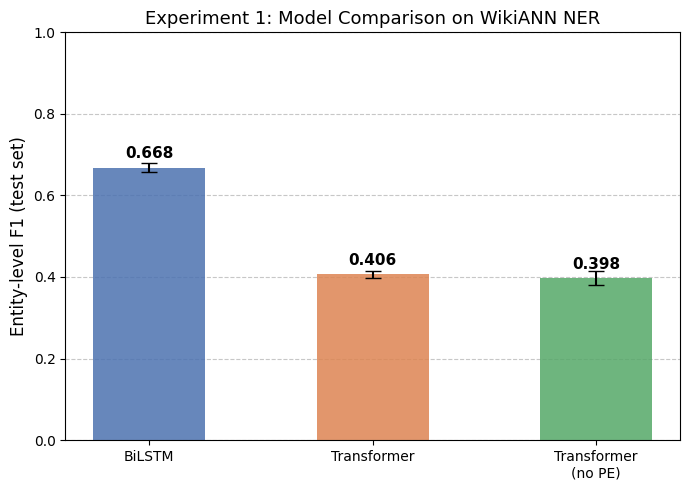

In [34]:
model_names = ["BiLSTM", "Transformer", "Transformer\n(no PE)"]
means  = [np.mean(bilstm_f1s), np.mean(trans_f1s), np.mean(trans_nope_f1s)]
stds   = [np.std(bilstm_f1s),  np.std(trans_f1s),  np.std(trans_nope_f1s)]
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(model_names, means, yerr=stds, capsize=6,
              color=colors, alpha=0.85, width=0.5)
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015, f"{m:.3f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("Entity-level F1 (test set)", fontsize=12)
ax.set_title("Experiment 1: Model Comparison on WikiANN NER", fontsize=13)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("exp1_baseline_comparison.png", dpi=150)
plt.show()

### Experiment 1b — Per-Entity F1 Breakdown

Reporting a single overall F1 hides variation across entity types. PER and LOC tend to be easier because names follow more consistent surface patterns, while ORG is harder due to greater ambiguity. Examining per-entity F1 allows a more nuanced comparison between architectures.

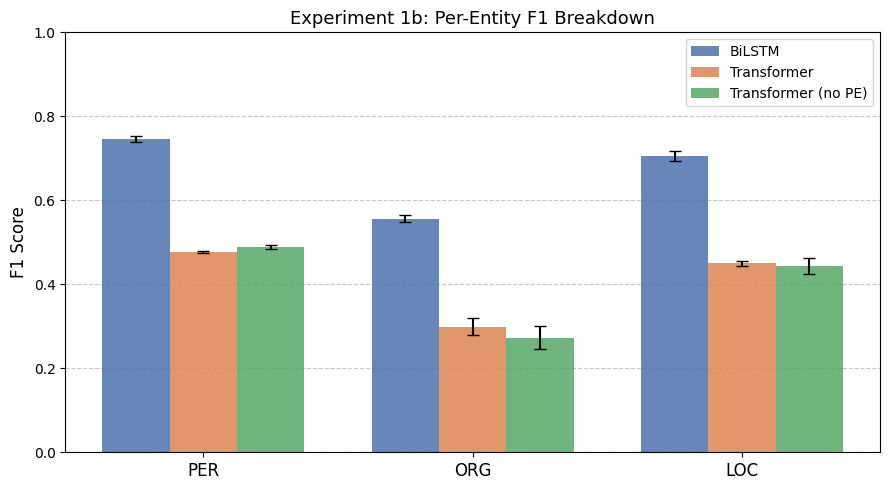

Entity            BiLSTM     Transformer   Trans (no PE)
--------------------------------------------------------
PER        0.747±0.007   0.476±0.002   0.488±0.005
ORG        0.556±0.009   0.299±0.020   0.273±0.028
LOC        0.706±0.011   0.450±0.006   0.444±0.019


In [35]:
ENTITY_TYPES = ["PER", "ORG", "LOC"]

def per_entity_f1_across_seeds(artefacts):
    seed_scores = {ent: [] for ent in ENTITY_TYPES}
    for preds, labels, _ in artefacts:
        report = seqeval_report(labels, preds, output_dict=True, zero_division=0)
        for ent in ENTITY_TYPES:
            seed_scores[ent].append(report.get(ent, {}).get("f1-score", 0.0))
    means = {ent: np.mean(seed_scores[ent]) for ent in ENTITY_TYPES}
    stds  = {ent: np.std(seed_scores[ent])  for ent in ENTITY_TYPES}
    return means, stds

bilstm_ent_means,     bilstm_ent_stds     = per_entity_f1_across_seeds(bilstm_artefacts)
trans_ent_means,      trans_ent_stds      = per_entity_f1_across_seeds(trans_artefacts)
trans_nope_ent_means, trans_nope_ent_stds = per_entity_f1_across_seeds(trans_nope_artefacts)

x, width = np.arange(len(ENTITY_TYPES)), 0.25
fig, ax  = plt.subplots(figsize=(9, 5))
for i, (means, stds, label, color) in enumerate([
    (bilstm_ent_means,     bilstm_ent_stds,     "BiLSTM",              "#4C72B0"),
    (trans_ent_means,      trans_ent_stds,      "Transformer",         "#DD8452"),
    (trans_nope_ent_means, trans_nope_ent_stds, "Transformer (no PE)", "#55A868"),
]):
    offset = (i - 1) * width
    ax.bar(x + offset, [means[e] for e in ENTITY_TYPES], width,
           yerr=[stds[e] for e in ENTITY_TYPES],
           capsize=4, label=label, color=color, alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(ENTITY_TYPES, fontsize=12)
ax.set_ylabel("F1 Score", fontsize=12)
ax.set_title("Experiment 1b: Per-Entity F1 Breakdown", fontsize=13)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("exp1b_per_entity_f1.png", dpi=150)
plt.show()

print(f"{'Entity':<8}", end="")
for label in ["BiLSTM", "Transformer", "Trans (no PE)"]:
    print(f"  {label:>14}", end="")
print()
print("-" * 56)
for ent in ENTITY_TYPES:
    print(f"{ent:<8}", end="")
    for means, stds in [
        (bilstm_ent_means,     bilstm_ent_stds),
        (trans_ent_means,      trans_ent_stds),
        (trans_nope_ent_means, trans_nope_ent_stds),
    ]:
        print(f"  {means[ent]:6.3f}±{stds[ent]:.3f}", end="")
    print()

## Experiment 2 — Sentence Length Analysis

**Hypothesis:** The Transformer's advantage over BiLSTM will grow as sentence length increases. For short sentences the BiLSTM's sequential hidden state can capture all relevant context without significant degradation, but for longer sentences the vanishing gradient problem means early tokens have diminishing influence on later predictions — whereas the Transformer's attention maintains direct connections between all token pairs regardless of distance.

Sentences are binned into Short (<10 tokens), Medium (10–25), and Long (>25). F1 is computed per seed for each bin and averaged, consistent with the overall F1 reporting.

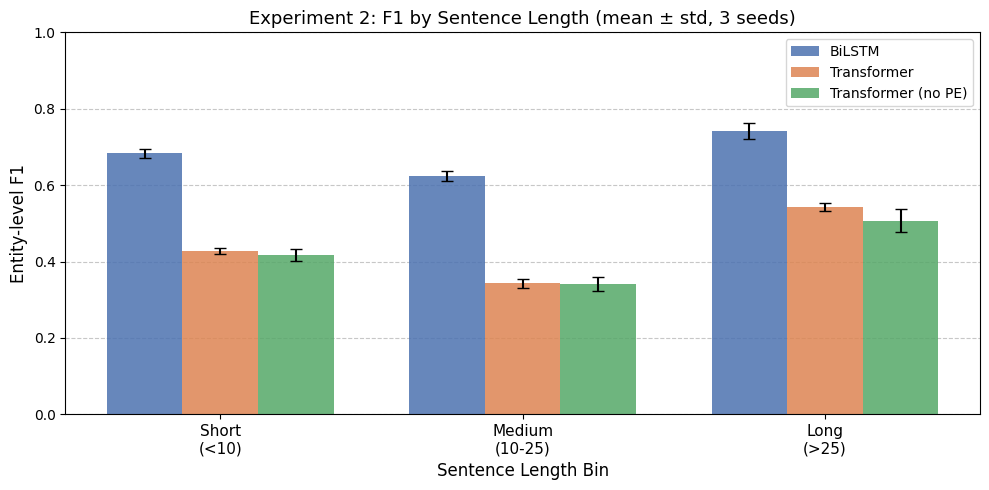

Bin                         BiLSTM     Transformer   Trans (no PE)
----------------------------------------------------------------
Short (<10)          0.683±0.012   0.427±0.008   0.417±0.016
Medium (10-25)       0.624±0.012   0.343±0.013   0.342±0.018
Long (>25)           0.741±0.021   0.542±0.010   0.507±0.031


In [36]:
BIN_DEFS = [
    ("Short\n(<10)",    lambda l: l < 10),
    ("Medium\n(10-25)", lambda l: 10 <= l <= 25),
    ("Long\n(>25)",     lambda l: l > 25),
]
BIN_KEYS = [b[0] for b in BIN_DEFS]

def f1_by_length_bins_across_seeds(artefacts):
    seed_bin_f1s = {key: [] for key, _ in BIN_DEFS}
    for preds, labels, lengths in artefacts:
        for bin_key, bin_fn in BIN_DEFS:
            bin_preds  = [p  for p,  l in zip(preds,  lengths) if bin_fn(l)]
            bin_labels = [lb for lb, l in zip(labels, lengths) if bin_fn(l)]
            if bin_preds:
                seed_bin_f1s[bin_key].append(seqeval_f1(bin_labels, bin_preds))
            else:
                seed_bin_f1s[bin_key].append(0.0)
    means = {k: np.mean(v) for k, v in seed_bin_f1s.items()}
    stds  = {k: np.std(v)  for k, v in seed_bin_f1s.items()}
    return means, stds

bilstm_bin_means,     bilstm_bin_stds     = f1_by_length_bins_across_seeds(bilstm_artefacts)
trans_bin_means,      trans_bin_stds      = f1_by_length_bins_across_seeds(trans_artefacts)
trans_nope_bin_means, trans_nope_bin_stds = f1_by_length_bins_across_seeds(trans_nope_artefacts)

x, width = np.arange(len(BIN_KEYS)), 0.25
fig, ax  = plt.subplots(figsize=(10, 5))
for i, (means, stds, label, color) in enumerate([
    (bilstm_bin_means,     bilstm_bin_stds,     "BiLSTM",              "#4C72B0"),
    (trans_bin_means,      trans_bin_stds,      "Transformer",         "#DD8452"),
    (trans_nope_bin_means, trans_nope_bin_stds, "Transformer (no PE)", "#55A868"),
]):
    offset = (i - 1) * width
    ax.bar(x + offset, [means[k] for k in BIN_KEYS], width,
           yerr=[stds[k] for k in BIN_KEYS],
           capsize=4, label=label, color=color, alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(BIN_KEYS, fontsize=11)
ax.set_xlabel("Sentence Length Bin", fontsize=12)
ax.set_ylabel("Entity-level F1", fontsize=12)
ax.set_title("Experiment 2: F1 by Sentence Length (mean ± std, 3 seeds)", fontsize=13)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("exp2_sentence_length.png", dpi=150)
plt.show()

print(f"{'Bin':<18}", end="")
for label in ["BiLSTM", "Transformer", "Trans (no PE)"]:
    print(f"  {label:>14}", end="")
print()
print("-" * 64)
for k in BIN_KEYS:
    print(f"{k.replace(chr(10),' '):<18}", end="")
    for means, stds in [
        (bilstm_bin_means,     bilstm_bin_stds),
        (trans_bin_means,      trans_bin_stds),
        (trans_nope_bin_means, trans_nope_bin_stds),
    ]:
        print(f"  {means[k]:6.3f}±{stds[k]:.3f}", end="")
    print()

## Experiment 3 — Positional Encoding Ablation

**Hypothesis:** Removing positional encoding will cause a measurable drop in F1 because without it the Transformer treats the sentence as an unordered bag of tokens. Word order is critical for NER — the same word can have a completely different entity type depending on its position relative to surrounding words — so the model should struggle without positional information.

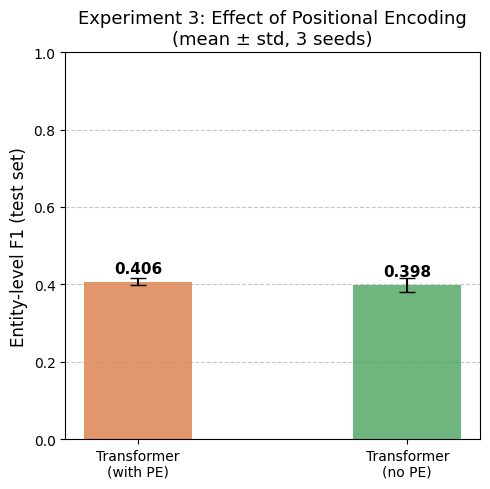

F1 drop from removing PE: 0.0087


In [37]:
labels_abl = ["Transformer\n(with PE)", "Transformer\n(no PE)"]
means_abl  = [np.mean(trans_f1s), np.mean(trans_nope_f1s)]
stds_abl   = [np.std(trans_f1s),  np.std(trans_nope_f1s)]

fig, ax = plt.subplots(figsize=(5, 5))
bars = ax.bar(labels_abl, means_abl, yerr=stds_abl, capsize=6,
              color=["#DD8452", "#55A868"], alpha=0.85, width=0.4)
for bar, m in zip(bars, means_abl):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015, f"{m:.3f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("Entity-level F1 (test set)", fontsize=12)
ax.set_title("Experiment 3: Effect of Positional Encoding\n(mean ± std, 3 seeds)", fontsize=13)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("exp3_positional_encoding_ablation.png", dpi=150)
plt.show()

print(f"F1 drop from removing PE: {means_abl[0] - means_abl[1]:.4f}")

## Experiment 4 — Dropout Sweep

**Hypothesis:** Both models will benefit from dropout regularisation, but the effect will be stronger for the Transformer. Without dropout, the Transformer is more prone to overfitting than the BiLSTM because its self-attention mechanism has far more parameters and can more easily memorise training data. The BiLSTM's sequential inductive bias acts as a natural regulariser, making it less sensitive to dropout rate.

Dropout values tested: 0.0, 0.3, 0.5.
The dropout=0.3 results are reused from the main training runs — only dropout=0.0 and dropout=0.5 require new training runs (12 additional runs).

> **Note:** This cell trains 12 new runs on top of the 9 already completed.

In [38]:
with open("/content/dropout_results.pkl", "rb") as f:
    dropout_results = pickle.load(f)

print("Loaded.")

Loaded.


In [39]:
DROPOUT_VALUES = [0.0, 0.3, 0.5]

# # Storage: dropout_results[model_name][dropout_value] = list of test F1s (one per seed)
# dropout_results = {
#     "BiLSTM":      {},
#     "Transformer": {}
# }

# # Reuse dropout=0.3 results from main runs (no retraining needed)
# dropout_results["BiLSTM"][0.3]      = bilstm_f1s
# dropout_results["Transformer"][0.3] = trans_f1s

# # Train dropout=0.0 and dropout=0.5 for both models
# for dropout_val in [0.0, 0.5]:
#     for model_name, factory in [
#         ("BiLSTM",      lambda d=dropout_val: make_bilstm(dropout=d)),
#         ("Transformer", lambda d=dropout_val: make_transformer(dropout=d)),
#     ]:
#         label = f"{model_name} dropout={dropout_val}"
#         f1s, _, _ = run_experiment(factory, label)
#         dropout_results[model_name][dropout_val] = f1s

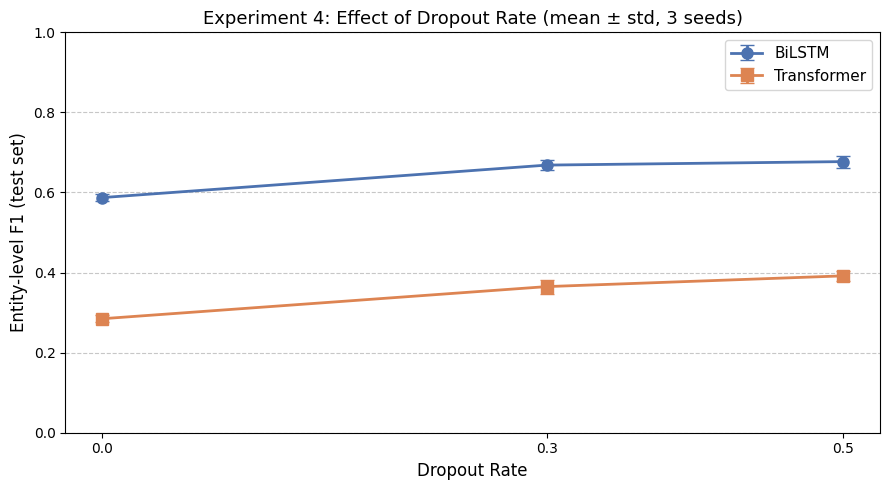

Dropout               BiLSTM       Transformer
----------------------------------------------
0.0          0.587±0.009   0.285±0.008
0.3          0.668±0.012   0.365±0.017
0.5          0.677±0.015   0.392±0.013


In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
colors  = {"BiLSTM": "#4C72B0", "Transformer": "#DD8452"}
markers = {"BiLSTM": "o",       "Transformer": "s"}

for model_name in ["BiLSTM", "Transformer"]:
    means = [np.mean(dropout_results[model_name][d]) for d in DROPOUT_VALUES]
    stds  = [np.std(dropout_results[model_name][d])  for d in DROPOUT_VALUES]
    ax.errorbar(DROPOUT_VALUES, means, yerr=stds,
                label=model_name,
                color=colors[model_name],
                marker=markers[model_name],
                markersize=8, linewidth=2, capsize=5)

ax.set_xlabel("Dropout Rate", fontsize=12)
ax.set_ylabel("Entity-level F1 (test set)", fontsize=12)
ax.set_title("Experiment 4: Effect of Dropout Rate (mean ± std, 3 seeds)", fontsize=13)
ax.set_xticks(DROPOUT_VALUES)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("exp4_dropout_sweep.png", dpi=150)
plt.show()

# Print table
print(f"{'Dropout':<10}", end="")
for model_name in ["BiLSTM", "Transformer"]:
    print(f"  {model_name:>16}", end="")
print()
print("-" * 46)
for d in DROPOUT_VALUES:
    print(f"{d:<10.1f}", end="")
    for model_name in ["BiLSTM", "Transformer"]:
        f1s = dropout_results[model_name][d]
        print(f"  {np.mean(f1s):6.3f}±{np.std(f1s):.3f}", end="")
    print()

## Learning Curves

Logged during the main training runs. Shaded region = ± 1 std across seeds.

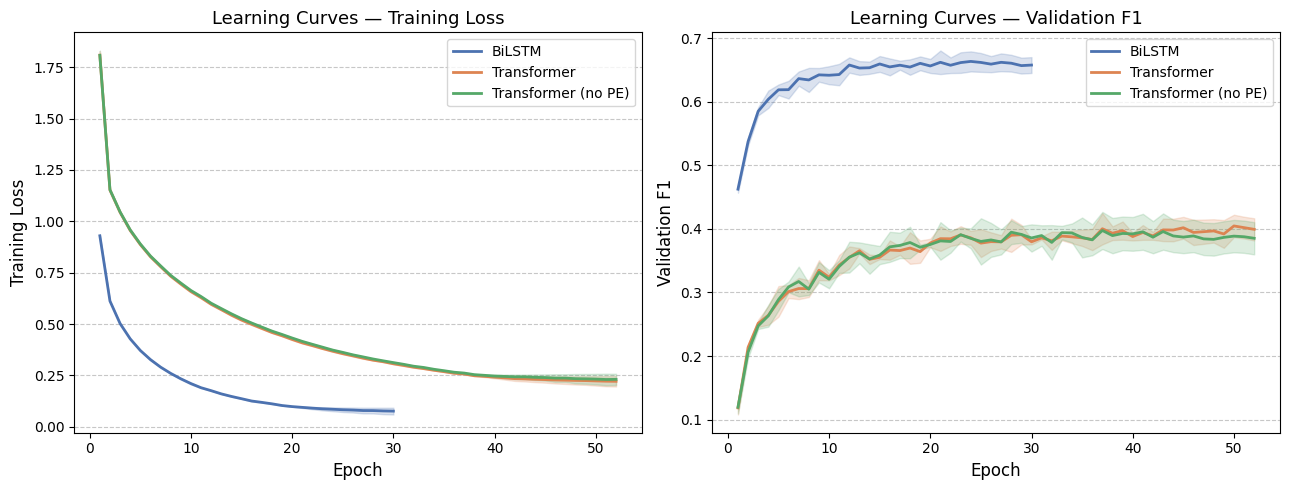

In [41]:
def pad_curves(curves):
    max_len = max(len(c) for c in curves)
    return np.array([c + [c[-1]] * (max_len - len(c)) for c in curves])

def plot_curve(ax, curves_list, idx, label, color):
    raw    = [c[idx] for c in curves_list]
    padded = pad_curves(raw)
    mean, std = padded.mean(0), padded.std(0)
    epochs = np.arange(1, len(mean) + 1)
    ax.plot(epochs, mean, label=label, color=color, linewidth=2)
    ax.fill_between(epochs, mean - std, mean + std, alpha=0.2, color=color)

fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(13, 5))
for curves, label, color in [
    (bilstm_curves,     "BiLSTM",              "#4C72B0"),
    (trans_curves,      "Transformer",         "#DD8452"),
    (trans_nope_curves, "Transformer (no PE)", "#55A868"),
]:
    plot_curve(ax_loss, curves, 0, label, color)
    plot_curve(ax_f1,  curves, 1, label, color)

for ax, ylabel, title in [
    (ax_loss, "Training Loss",  "Learning Curves — Training Loss"),
    (ax_f1,   "Validation F1", "Learning Curves — Validation F1"),
]:
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel(ylabel,  fontsize=12)
    ax.set_title(title,    fontsize=13)
    ax.legend(fontsize=10)
    ax.yaxis.grid(True, linestyle="--", alpha=0.7)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("exp_learning_curves.png", dpi=150)
plt.show()


## Summary Table

In [42]:
print("=" * 55)
print(f"{'Model':<25} {'Test F1':>10} {'Std':>8}")
print("=" * 55)
for name, f1s in [
    ("BiLSTM",              bilstm_f1s),
    ("Transformer",         trans_f1s),
    ("Transformer (no PE)", trans_nope_f1s),
]:
    print(f"{name:<25} {np.mean(f1s):>10.4f} {np.std(f1s):>8.4f}")
print("=" * 55)

print("\nDropout sweep (Test F1):")
print("=" * 46)
print(f"{'Dropout':<10}", end="")
for model_name in ["BiLSTM", "Transformer"]:
    print(f"  {model_name:>16}", end="")
print()
print("-" * 46)
for d in DROPOUT_VALUES:
    print(f"{d:<10.1f}", end="")
    for model_name in ["BiLSTM", "Transformer"]:
        f1s = dropout_results[model_name][d]
        print(f"  {np.mean(f1s):6.3f}±{np.std(f1s):.3f}", end="")
    print()
print("=" * 46)

Model                        Test F1      Std
BiLSTM                        0.6684   0.0118
Transformer                   0.4065   0.0092
Transformer (no PE)           0.3977   0.0174

Dropout sweep (Test F1):
Dropout               BiLSTM       Transformer
----------------------------------------------
0.0          0.587±0.009   0.285±0.008
0.3          0.668±0.012   0.365±0.017
0.5          0.677±0.015   0.392±0.013


## Retrained Transformer results with more patience

In [43]:
with open("/content/all_results_patience15.pkl", "rb") as f:
    results = pickle.load(f)

bilstm_f1s           = results["bilstm_f1s"]
bilstm_curves        = results["bilstm_curves"]
bilstm_artefacts     = results["bilstm_artefacts"]
trans_f1s            = results["trans_f1s"]
trans_curves         = results["trans_curves"]
trans_artefacts      = results["trans_artefacts"]
trans_nope_f1s       = results["trans_nope_f1s"]
trans_nope_curves    = results["trans_nope_curves"]
trans_nope_artefacts = results["trans_nope_artefacts"]

print("Loaded.")

Loaded.


In [44]:
# # Retrain Transformer only, with more patience
# NUM_EPOCHS = 60
# PATIENCE   = 15

# trans_f1s,      trans_curves,      trans_artefacts      = run_experiment(
#     make_transformer, "Transformer")

# trans_nope_f1s, trans_nope_curves, trans_nope_artefacts = run_experiment(
#     lambda: make_transformer(use_pe=False), "Transformer (no PE)")

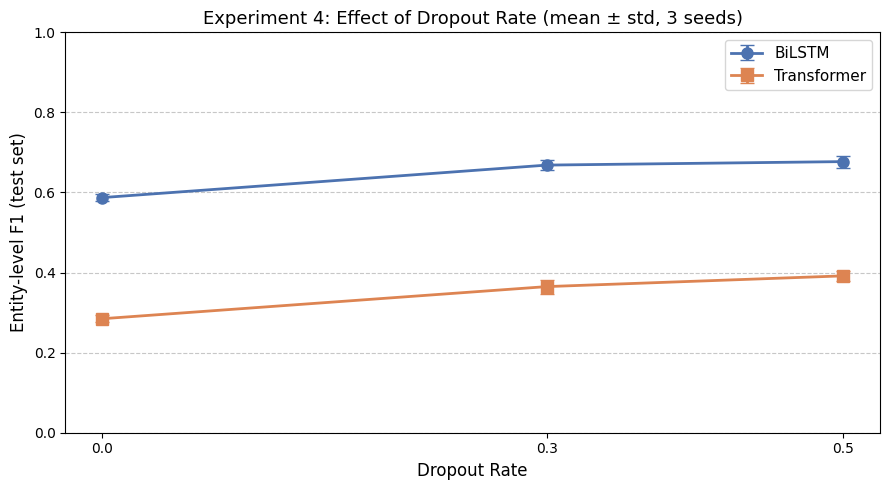

Dropout               BiLSTM       Transformer
----------------------------------------------
0.0          0.587±0.009   0.285±0.008
0.3          0.668±0.012   0.365±0.017
0.5          0.677±0.015   0.392±0.013


In [45]:
fig, ax = plt.subplots(figsize=(9, 5))
colors  = {"BiLSTM": "#4C72B0", "Transformer": "#DD8452"}
markers = {"BiLSTM": "o",       "Transformer": "s"}

for model_name in ["BiLSTM", "Transformer"]:
    means = [np.mean(dropout_results[model_name][d]) for d in DROPOUT_VALUES]
    stds  = [np.std(dropout_results[model_name][d])  for d in DROPOUT_VALUES]
    ax.errorbar(DROPOUT_VALUES, means, yerr=stds,
                label=model_name,
                color=colors[model_name],
                marker=markers[model_name],
                markersize=8, linewidth=2, capsize=5)

ax.set_xlabel("Dropout Rate", fontsize=12)
ax.set_ylabel("Entity-level F1 (test set)", fontsize=12)
ax.set_title("Experiment 4: Effect of Dropout Rate (mean ± std, 3 seeds)", fontsize=13)
ax.set_xticks(DROPOUT_VALUES)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("exp4_dropout_sweep.png", dpi=150)
plt.show()

# Print table
print(f"{'Dropout':<10}", end="")
for model_name in ["BiLSTM", "Transformer"]:
    print(f"  {model_name:>16}", end="")
print()
print("-" * 46)
for d in DROPOUT_VALUES:
    print(f"{d:<10.1f}", end="")
    for model_name in ["BiLSTM", "Transformer"]:
        f1s = dropout_results[model_name][d]
        print(f"  {np.mean(f1s):6.3f}±{np.std(f1s):.3f}", end="")
    print()

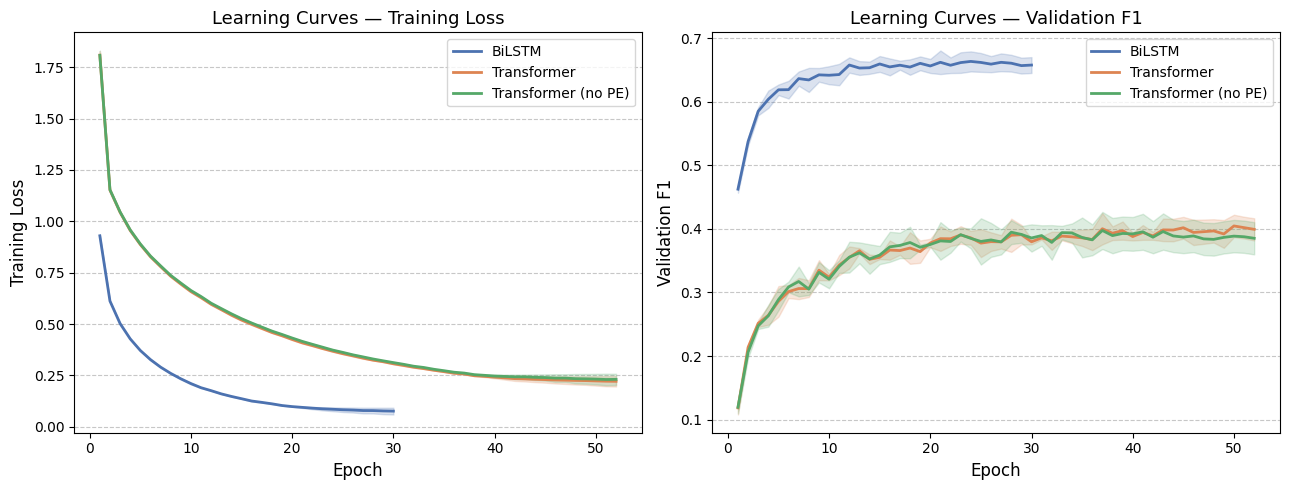

In [46]:
def pad_curves(curves):
    max_len = max(len(c) for c in curves)
    return np.array([c + [c[-1]] * (max_len - len(c)) for c in curves])

def plot_curve(ax, curves_list, idx, label, color):
    raw    = [c[idx] for c in curves_list]
    padded = pad_curves(raw)
    mean, std = padded.mean(0), padded.std(0)
    epochs = np.arange(1, len(mean) + 1)
    ax.plot(epochs, mean, label=label, color=color, linewidth=2)
    ax.fill_between(epochs, mean - std, mean + std, alpha=0.2, color=color)

fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(13, 5))
for curves, label, color in [
    (bilstm_curves,     "BiLSTM",              "#4C72B0"),
    (trans_curves,      "Transformer",         "#DD8452"),
    (trans_nope_curves, "Transformer (no PE)", "#55A868"),
]:
    plot_curve(ax_loss, curves, 0, label, color)
    plot_curve(ax_f1,  curves, 1, label, color)

for ax, ylabel, title in [
    (ax_loss, "Training Loss",  "Learning Curves — Training Loss"),
    (ax_f1,   "Validation F1", "Learning Curves — Validation F1"),
]:
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel(ylabel,  fontsize=12)
    ax.set_title(title,    fontsize=13)
    ax.legend(fontsize=10)
    ax.yaxis.grid(True, linestyle="--", alpha=0.7)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("exp_learning_curves.png", dpi=150)
plt.show()

In [47]:
print("=" * 55)
print(f"{'Model':<25} {'Test F1':>10} {'Std':>8}")
print("=" * 55)
for name, f1s in [
    ("BiLSTM",              bilstm_f1s),
    ("Transformer",         trans_f1s),
    ("Transformer (no PE)", trans_nope_f1s),
]:
    print(f"{name:<25} {np.mean(f1s):>10.4f} {np.std(f1s):>8.4f}")
print("=" * 55)

print("\nDropout sweep (Test F1):")
print("=" * 46)
print(f"{'Dropout':<10}", end="")
for model_name in ["BiLSTM", "Transformer"]:
    print(f"  {model_name:>16}", end="")
print()
print("-" * 46)
for d in DROPOUT_VALUES:
    print(f"{d:<10.1f}", end="")
    for model_name in ["BiLSTM", "Transformer"]:
        f1s = dropout_results[model_name][d]
        print(f"  {np.mean(f1s):6.3f}±{np.std(f1s):.3f}", end="")
    print()
print("=" * 46)

Model                        Test F1      Std
BiLSTM                        0.6684   0.0118
Transformer                   0.4065   0.0092
Transformer (no PE)           0.3977   0.0174

Dropout sweep (Test F1):
Dropout               BiLSTM       Transformer
----------------------------------------------
0.0          0.587±0.009   0.285±0.008
0.3          0.668±0.012   0.365±0.017
0.5          0.677±0.015   0.392±0.013
